# Exploratory data analysis (EDA) of dataframe containing daily activity, steps, and sleep data

1. Importing packages, pre-cleaned datasets, and verifying that no data is lost between notebooks. See notebooks/data_cleaning.ipynb for details on data-cleaning process.

In [192]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

#setting the theme for the plots
sns.set_theme(style="ticks", palette="muted")

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 11

In [193]:
#Importing cleaned datasets
df_daily_clean = pd.read_csv("daily_merged_clean.csv")

#verifying data accuracy - missing values
print("Records with missing sleep info in daily dataset:", df_daily_clean['HoursInBed'].isna().sum())
print("Records with complete sleep info in daily dataset:", df_daily_clean['HoursInBed'].notna().sum())

#inspecting shape and datatypes
print("Shape of df_daily_clean:", df_daily_clean.shape)

print("Data types in df_daily_clean:")
print(df_daily_clean.dtypes)

Records with missing sleep info in daily dataset: 530
Records with complete sleep info in daily dataset: 410
Shape of df_daily_clean: (940, 25)
Data types in df_daily_clean:
Id                            int64
ActivityDate                    str
TotalSteps                    int64
TotalDistance               float64
TrackerDistance             float64
LoggedActivitiesDistance    float64
VeryActiveDistance          float64
ModeratelyActiveDistance    float64
LightActiveDistance         float64
SedentaryActiveDistance     float64
VeryActiveMinutes             int64
FairlyActiveMinutes           int64
LightlyActiveMinutes          int64
SedentaryMinutes              int64
Calories                      int64
Day_of_the_week                 str
Is_Weekend                     bool
TotalTrackerMinutes           int64
ValidWearDay                   bool
TotalSleepRecords           float64
TotalMinutesAsleep          float64
TotalTimeInBed              float64
HoursAsleep                 float6

In [194]:
#converting the date columns to datetime format
df_daily_clean['Date'] = pd.to_datetime(df_daily_clean['ActivityDate'])

print(df_daily_clean.head())

#verifying the date columns are in datetime format
print(df_daily_clean.dtypes)



           Id ActivityDate  TotalSteps  TotalDistance  TrackerDistance  \
0  1503960366    4/12/2016       13162           8.50             8.50   
1  1624580081    4/12/2016        8163           5.31             5.31   
2  1644430081    4/12/2016       10694           7.77             7.77   
3  1844505072    4/12/2016        6697           4.43             4.43   
4  1927972279    4/12/2016         678           0.47             0.47   

   LoggedActivitiesDistance  VeryActiveDistance  ModeratelyActiveDistance  \
0                       0.0                1.88                      0.55   
1                       0.0                0.00                      0.00   
2                       0.0                0.14                      2.30   
3                       0.0                0.00                      0.00   
4                       0.0                0.00                      0.00   

   LightActiveDistance  SedentaryActiveDistance  ...  Is_Weekend  \
0                 6.06  

2. Daily dataset records were previously categorized into valid wear and non-valid wear days based on the assumtion: Valid wear day =  Tracker worn for >= 10 hours (600 mins) and steps > 0. 

* A new subset dataframe `df_daily_valid_Wear` is created with only records considered valid wear days for daily activity analysis downstream, while retaining the original dataframe for sleep analysis. 
* Inspecting and visualizing use wear-patterns using `wear_ratio`

Valid wear days per user:
Id
1503960366    30
1624580081    31
1644430081    30
1844505072    20
1927972279    17
2022484408    31
2026352035    31
2320127002    31
2347167796    17
2873212765    31
3372868164    20
3977333714    29
4020332650    17
4057192912     3
4319703577    30
4388161847    31
4445114986    30
4558609924    31
4702921684    29
5553957443    29
5577150313    27
6117666160    22
6290855005    24
6775888955    17
6962181067    30
7007744171    24
7086361926    29
8053475328    31
8253242879    18
8378563200    30
8583815059    30
8792009665    19
8877689391    31
dtype: int64
Non-valid wear days per user:
Id
1503960366     1
1844505072    11
1927972279    14
2347167796     1
3977333714     1
4020332650    14
4057192912     1
4319703577     1
4445114986     1
4702921684     2
5553957443     2
5577150313     3
6117666160     6
6290855005     5
6775888955     9
6962181067     1
7007744171     2
7086361926     2
8253242879     1
8378563200     1
8583815059     1
8792009

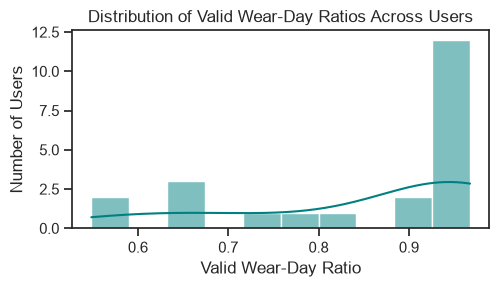

In [195]:
df_daily_valid_wear = df_daily_clean.loc[df_daily_clean['ValidWearDay'] == True]

#counting the number of valid wear days vs non-valid wear days per user
valid_wear_counts = df_daily_valid_wear.groupby('Id').size()
non_valid_wear_counts = df_daily_clean.loc[df_daily_clean['ValidWearDay'] == False].groupby('Id').size()

print("Valid wear days per user:")
print(valid_wear_counts)
print("Non-valid wear days per user:")
print(non_valid_wear_counts)

#describing the ratio of valid wear days to total days per user
wear_ratio = valid_wear_counts / (valid_wear_counts + non_valid_wear_counts)
wear_ratio_summary = wear_ratio.describe()
print("Summary statistics for the ratio of valid wear days to total days per user:")
print(wear_ratio_summary)

# Plotting the distribution of valid wear-day ratios across users
fig, axes = plt.subplots(1, 1, figsize=(5, 3))

sns.histplot(wear_ratio, bins=10, kde=True, ax=axes, color="teal")
axes.set_title("Distribution of Valid Wear-Day Ratios Across Users")
axes.set_xlabel("Valid Wear-Day Ratio")
axes.set_ylabel("Number of Users")


plt.tight_layout()
plt.show()


Observation: 
* Distribution is heavily left-skewed. 
* Reasonable to assume that most participants wore the device consistently 
* Clustering near the ceiling - suggesting a possibility of separate cohort of users that wore the device almost everyday

In [196]:
#verifying that the df_valid_wear dataframe matches the expected rows from df_daily_clean
expected = df_daily_clean.loc[df_daily_clean["ValidWearDay"] == True]

print(f"True rows in df_daily_clean: {len(expected)}")
print(f"Rows in df_daily_valid_wear:       {len(df_daily_valid_wear)}")
print(f"DataFrames match:            {df_daily_valid_wear.equals(expected)}")

assert df_daily_valid_wear.equals(expected), "The rows do not match."

True rows in df_daily_clean: 850
Rows in df_daily_valid_wear:       850
DataFrames match:            True


3. Before filtering for valid wear days, the `df_daily_clean` dataset had 530 records with missing sleep info which is 530/940 = 56.38% of the total records and 410 records with complete sleep info. These missing value records were intentionally left in the dataset to avoid unneecessary data loss. However, for the purpose of direct bivariate analysis between sleep and activity, we will create a new dataframe `df_daily_paired` with only the records with complete sleep info.

In [197]:
df_daily_paired = df_daily_valid_wear[df_daily_valid_wear['HoursInBed'].notna()].copy()

#to verify that the new dataframe has only records with complete sleep info, we will check the number of records with missing sleep info in the new dataframe.
print("Records with missing sleep info in df_daily_paired:", df_daily_paired['HoursInBed'].isna().sum())
print("Records with complete sleep info in df_daily_paired:", df_daily_paired['HoursInBed'].notna().sum())

Records with missing sleep info in df_daily_paired: 0
Records with complete sleep info in df_daily_paired: 398


4.a. Visualizing the distribution of sleep duration in the df_daily_paired dataset to determine appropriate cutoffs for filtering out extreme values

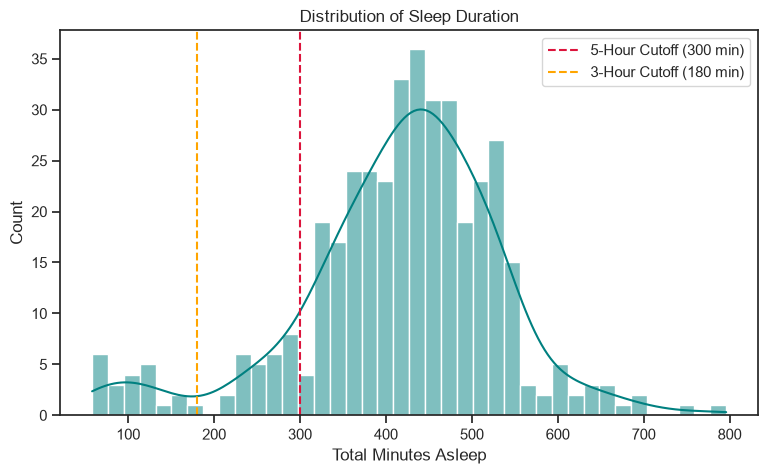

In [198]:

sns.histplot(df_daily_paired["TotalMinutesAsleep"].dropna(), bins=40, kde=True, color="teal")
plt.axvline(300, color="crimson", linestyle="--", label="5-Hour Cutoff (300 min)")
plt.axvline(180, color="orange", linestyle="--", label="3-Hour Cutoff (180 min)")
plt.xlabel("Total Minutes Asleep")
plt.title("Distribution of Sleep Duration")
plt.legend()
plt.show()

4.b. Stratification of sleep duration
* Removing extreme values from the df_daily_paired dataset based on the visualized distribution. 
* Removing records with TotalMinutesAsleep < 30 minutes and > 780 minutes (false positives or sensor stationary on a table).
* Removing records with sleep efficiency <30% (likely false positive or sensor stationary on a table).
* Categorizing sleep duration into three categories: Naps (< 180 minutes), Short Sleep (180-300 minutes), and Long Sleep (> 300 minutes)

Distribution of Sleep Categories:
SleepCategory
Long Sleep     347
Short Sleep     28
Naps            22
Name: count, dtype: int64


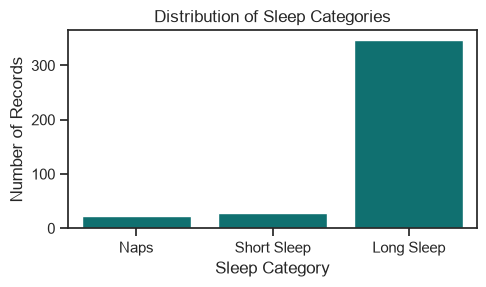

In [199]:
# Keep records meeting all sleep-quality and duration criteria
df_daily_paired = df_daily_paired.loc[
    (df_daily_paired["SleepEfficiency"] >= 0.30)
    & df_daily_paired["TotalMinutesAsleep"].between(30, 780, inclusive="both")
]

df_daily_paired["SleepCategory"] = pd.cut(df_daily_paired["TotalMinutesAsleep"], bins=[0, 180, 300, float('inf')], labels=["Naps", "Short Sleep", "Long Sleep"])


# Display the distribution of sleep categories
sleep_category_counts = df_daily_paired["SleepCategory"].value_counts()
print("Distribution of Sleep Categories:")
print(sleep_category_counts)

# Plotting the distribution of sleep categories
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
sns.countplot(x="SleepCategory", data=df_daily_paired, order=["Naps", "Short Sleep", "Long Sleep"], ax=ax, color="teal")
ax.set_title("Distribution of Sleep Categories")
ax.set_xlabel("Sleep Category")
ax.set_ylabel("Number of Records")
plt.tight_layout()
plt.show()

Observation: A large number of sleep durations classified as "long-sleep". This can be used as a stand-alone metric for nocturnal sleep. The "naps" and "short sleep" categories may be used as needed.

In [200]:
#verifying that the filtering and categorization worked as expected
print("Records with missing sleep info in df_daily_paired after filtering:", df_daily_paired['HoursInBed'].isna().sum())
print("Records with complete sleep info in df_daily_paired after filtering:", df_daily_paired['HoursInBed'].notna().sum())
print("Records with sleep efficiency < 30% in df_daily_paired after filtering:", (df_daily_paired['SleepEfficiency'] < 0.30).sum())
print("Records with TotalMinutesAsleep < 30 or > 780 in df_daily_paired after filtering:", ((df_daily_paired['TotalMinutesAsleep'] < 30) | (df_daily_paired['TotalMinutesAsleep'] > 780)).sum())

Records with missing sleep info in df_daily_paired after filtering: 0
Records with complete sleep info in df_daily_paired after filtering: 397
Records with sleep efficiency < 30% in df_daily_paired after filtering: 0
Records with TotalMinutesAsleep < 30 or > 780 in df_daily_paired after filtering: 0


### Investigating univariate distributions in baseline variables

5. The granularity of all daily dataframes in this analysis is in terms of person-day. Therefore, there are two ways to analyze univariate trends - pooled vs average per person. The pooled approach looks at the distribution of all daily steps across all users, while the average per person approach looks at the average daily steps for each user and then analyzes the distribution of those averages.

Pooled vs per-person average for daily activity metrics

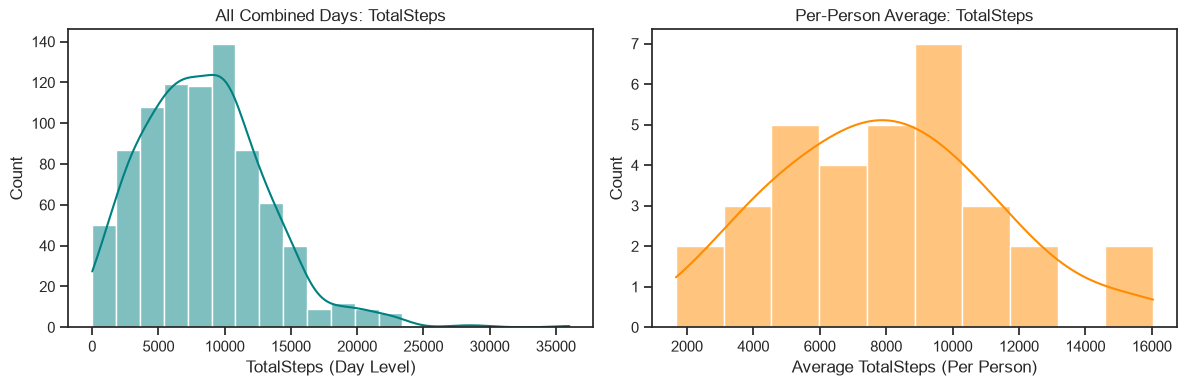

=== TotalSteps Summary ===
All Days Combined  -> Mean: 8407.7, Median: 8148.0
Per-Person Average -> Mean: 8008.2, Median: 7555.8
--------------------------------------------------


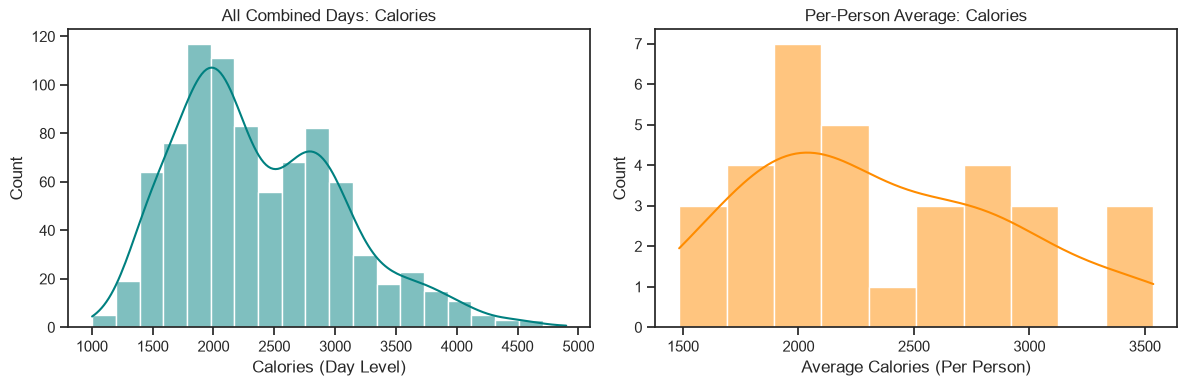

=== Calories Summary ===
All Days Combined  -> Mean: 2380.8, Median: 2225.0
Per-Person Average -> Mean: 2360.1, Median: 2218.7
--------------------------------------------------


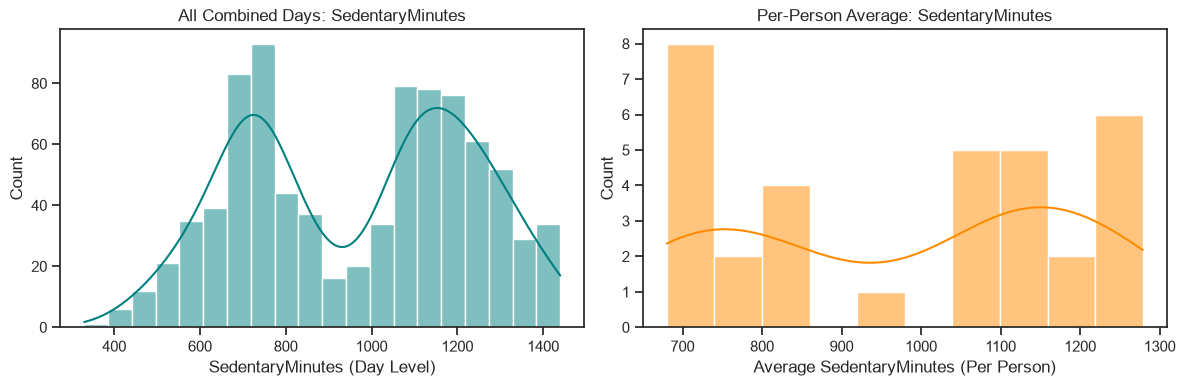

=== SedentaryMinutes Summary ===
All Days Combined  -> Mean: 967.0, Median: 1030.0
Per-Person Average -> Mean: 980.6, Median: 1077.5
--------------------------------------------------


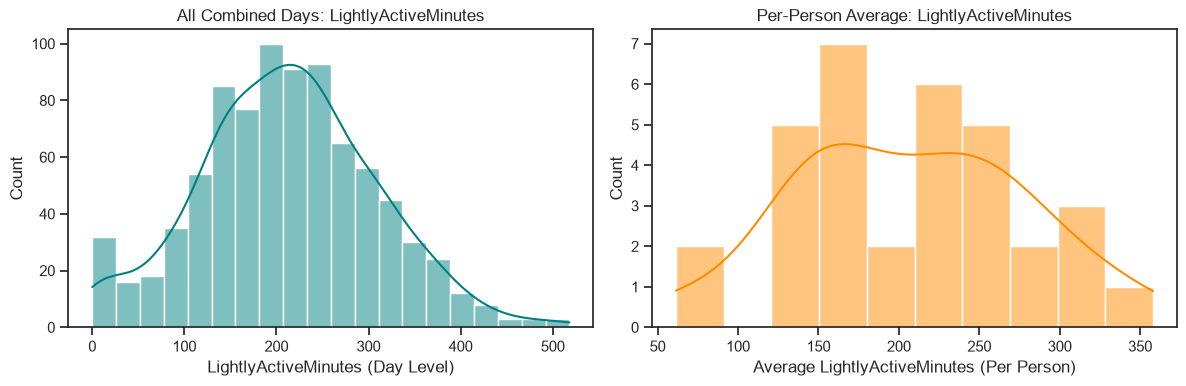

=== LightlyActiveMinutes Summary ===
All Days Combined  -> Mean: 212.1, Median: 211.5
Per-Person Average -> Mean: 206.6, Median: 214.1
--------------------------------------------------


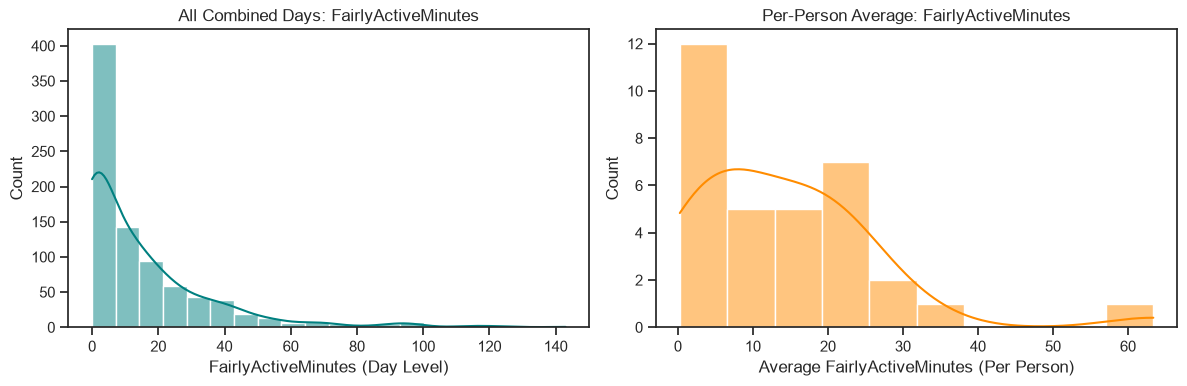

=== FairlyActiveMinutes Summary ===
All Days Combined  -> Mean: 15.0, Median: 8.0
Per-Person Average -> Mean: 14.2, Median: 12.7
--------------------------------------------------


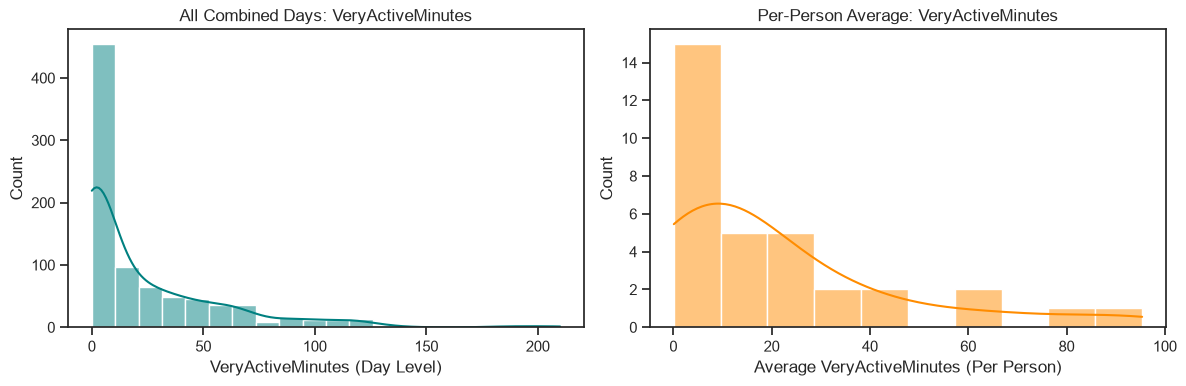

=== VeryActiveMinutes Summary ===
All Days Combined  -> Mean: 23.3, Median: 7.0
Per-Person Average -> Mean: 21.3, Median: 10.4
--------------------------------------------------


In [201]:
daily_metrics = [
    "TotalSteps",
    "Calories",
    "SedentaryMinutes",
    "LightlyActiveMinutes",
    "FairlyActiveMinutes",
    "VeryActiveMinutes",
]
# Looping through each metric and compare both views side-by-side
for col in daily_metrics:
    #Per-person averages
    person_avg = df_daily_valid_wear.groupby('Id')[col].mean()
    
    #Side-by-side plots
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    #Left:All combined
    sns.histplot(df_daily_valid_wear[col], kde=True, ax=axes[0], color='teal', bins=20)
    axes[0].set_title(f"All Combined Days: {col}")
    axes[0].set_xlabel(f"{col} (Day Level)")
    
    #Right:Per-person Average
    sns.histplot(person_avg, kde=True, ax=axes[1], color='darkorange', bins=10)
    axes[1].set_title(f"Per-Person Average: {col}")
    axes[1].set_xlabel(f"Average {col} (Per Person)")
    
    plt.tight_layout()
    plt.show()

    #Printing comparison stats
    print(f"=== {col} Summary ===")
    print(f"All Days Combined  -> Mean: {df_daily_valid_wear[col].mean():.1f}, Median: {df_daily_valid_wear[col].median():.1f}")
    print(f"Per-Person Average -> Mean: {person_avg.mean():.1f}, Median: {person_avg.median():.1f}")
    print("-" * 50)


Pooled vs per-person average for sleep metrics

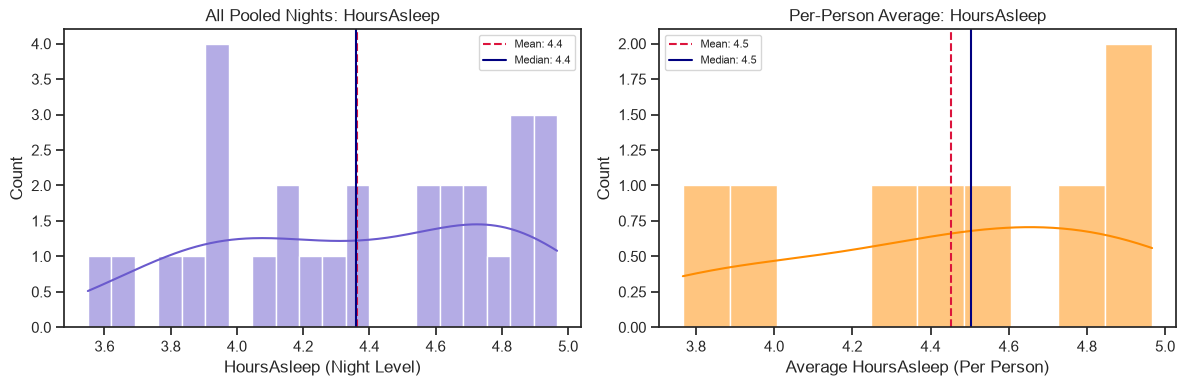

=== HoursAsleep Summary ===
Pooled Nights  -> Mean: 4.36, Median: 4.36, Skew: -0.20
Person Average -> Mean: 4.45, Median: 4.50, Skew: -0.35
-------------------------------------------------------


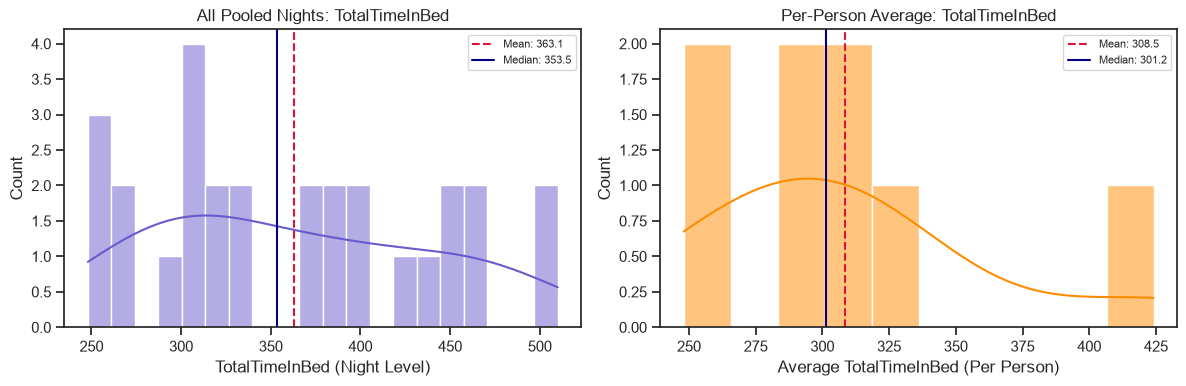

=== TotalTimeInBed Summary ===
Pooled Nights  -> Mean: 363.07, Median: 353.50, Skew: 0.29
Person Average -> Mean: 308.49, Median: 301.17, Skew: 1.14
-------------------------------------------------------


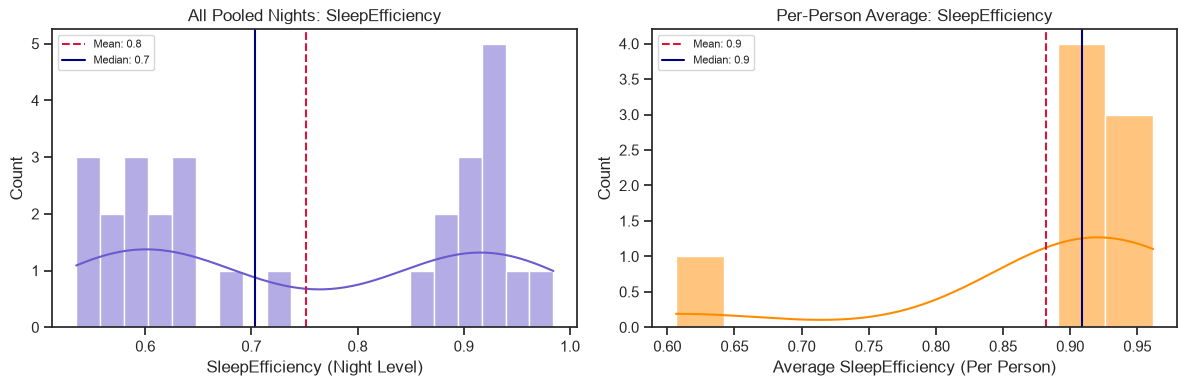

=== SleepEfficiency Summary ===
Pooled Nights  -> Mean: 0.75, Median: 0.70, Skew: 0.05
Person Average -> Mean: 0.88, Median: 0.91, Skew: -2.09
-------------------------------------------------------


In [202]:
# Removing naps from the sleep metrics analysis to focus on full sleep patterns. Naps are defined as sleep durations less than 180 minutes.
df_nocturnal = df_daily_paired[
    df_daily_paired['SleepCategory'].isin(['Short Sleep', 'Full Sleep'])
].copy()


sleep_metrics = ["HoursAsleep", "TotalTimeInBed", "SleepEfficiency"]

for col in sleep_metrics:
    person_avg = df_nocturnal.groupby("Id")[col].mean()
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    #Left:all pooled nights
    sns.histplot(df_nocturnal[col].dropna(), kde=True, ax=axes[0], color="slateblue", bins=20)
    axes[0].set_title(f"All Pooled Nights: {col}")
    axes[0].set_xlabel(f"{col} (Night Level)")
    axes[0].axvline(df_nocturnal[col].mean(), color="crimson", linestyle="--", label=f"Mean: {df_nocturnal[col].mean():.1f}")
    axes[0].axvline(df_nocturnal[col].median(), color="navy", linestyle="-", label=f"Median: {df_nocturnal[col].median():.1f}")
    axes[0].legend(fontsize=8)
    
    #Right:Per-person Averages
    sns.histplot(person_avg.dropna(), kde=True, ax=axes[1], color="darkorange", bins=10)
    axes[1].set_title(f"Per-Person Average: {col}")
    axes[1].set_xlabel(f"Average {col} (Per Person)")
    axes[1].axvline(person_avg.mean(), color="crimson", linestyle="--", label=f"Mean: {person_avg.mean():.1f}")
    axes[1].axvline(person_avg.median(), color="navy", linestyle="-", label=f"Median: {person_avg.median():.1f}")
    axes[1].legend(fontsize=8)
    
    plt.tight_layout()
    plt.show()

    #comparison
    skew_pooled = stats.skew(df_nocturnal[col].dropna())
    skew_person = stats.skew(person_avg.dropna())
    print(f"=== {col} Summary ===")
    print(f"Pooled Nights  -> Mean: {df_nocturnal[col].mean():.2f}, Median: {df_nocturnal[col].median():.2f}, Skew: {skew_pooled:.2f}")
    print(f"Person Average -> Mean: {person_avg.mean():.2f}, Median: {person_avg.median():.2f}, Skew: {skew_person:.2f}")
    print("-" * 55)


Overall comparison of pooled vs per-person averages of metrics (between-group vs in-group)

In [203]:
metrics = [
    'TotalSteps',
    'Calories',
    'SedentaryMinutes',
    'LightlyActiveMinutes'
]

#pooled (all days combined) statistics
pooled_mean = df_daily_valid_wear[metrics].mean()
pooled_median = df_daily_valid_wear[metrics].median()

#per-person average statistics (one mean per Id)
user_means = df_daily_valid_wear.groupby('Id')[metrics].mean()
person_mean = user_means.mean()
person_median = user_means.median()

#comparison dataframe
diff_table = pd.DataFrame({
    'Pooled_Mean': pooled_mean,
    'Person_Mean': person_mean,
    'Mean_Diff (Person - Pooled)': person_mean - pooled_mean,
    'Pooled_Median': pooled_median,
    'Person_Median': person_median,
    'Median_Diff (Person - Pooled)': person_median - pooled_median
})

#formatting
diff_table = diff_table.round(1)
print("=== Comparison: Pooled Days (N=850) vs. Per-Person Averages (N=33) ===")
display(diff_table)

#pooled statistics (all nocturnal nights combined)
pooled_sleep_mean = df_nocturnal[sleep_metrics].mean()
pooled_sleep_median = df_nocturnal[sleep_metrics].median()

#per-person average statistics (one mean per participant)
user_sleep_means = df_nocturnal.groupby('Id')[sleep_metrics].mean()
person_sleep_mean = user_sleep_means.mean()
person_sleep_median = user_sleep_means.median()

#comparison table
sleep_diff_table = pd.DataFrame({
    'Pooled_Mean': pooled_sleep_mean,
    'Person_Mean': person_sleep_mean,
    'Mean_Diff (Person - Pooled)': person_sleep_mean - pooled_sleep_mean,
    'Pooled_Median': pooled_sleep_median,
    'Person_Median': person_sleep_median,
    'Median_Diff (Person - Pooled)': person_sleep_median - pooled_sleep_median
}).round(2)

print(f"=== Nocturnal Sleep Comparison (N_nights={len(df_nocturnal)}, N_users={df_nocturnal['Id'].nunique()}) ===")
display(sleep_diff_table)





=== Comparison: Pooled Days (N=850) vs. Per-Person Averages (N=33) ===


,Pooled_Mean,Person_Mean,Mean_Diff (Person - Pooled),Pooled_Median,Person_Median,Median_Diff (Person - Pooled)
TotalSteps,8407.7,8008.2,-399.5,8148.0,7555.8,-592.2
Calories,2380.8,2360.1,-20.7,2225.0,2218.7,-6.3
SedentaryMinutes,967.0,980.6,13.6,1030.0,1077.6,47.5
LightlyActiveMinutes,212.1,206.6,-5.5,211.5,214.1,2.6


=== Nocturnal Sleep Comparison (N_nights=28, N_users=8) ===


,Pooled_Mean,Person_Mean,Mean_Diff (Person - Pooled),Pooled_Median,Person_Median,Median_Diff (Person - Pooled)
HoursAsleep,4.36,4.45,0.09,4.36,4.50,0.14
TotalTimeInBed,363.07,308.49,-54.58,353.50,301.17,-52.33
SleepEfficiency,0.75,0.88,0.13,0.70,0.91,0.21


Important EDA findings from univariate analysis of daily activity data:

* Pooled vs Average per-person analysis
    * Metrics that differ: 
    * Total steps: The pooled mean (~8,408 steps) is higher than the per-person mean (~8,008 steps). Active participants probably wore the tracker for more days which disproportionately pulled the pooled average upward.
    * Sedentary minutes: The per-person median (~1,078 min) is noticeably higher than the pooled median (~1,030 min). Folowing the same trend as total steps, active participants probably wore the tracker for more days which artifically pulled the pooled Sedentary minutes down.

* Metrics that stay consistent
    * Calories & Light activity: Minimal difference possibly due to similar everyday routine movement across participants
    * Sleep metrics: Nearly identical hours asleep and sleep efficiency metrics (possible consistent device use)

Distribution characteristics (from pooled data)
* Total steps and calories: Roughly symmetric, unimodal - suitable for regression models
* Sedentary minutes: Negative kurtosis in the middle and bimodal - possible explanations include extreme clustering of active and sedentary participants, or higher sedentary values arising from device non-wear during unlogged sleep periods.
* Light active minutes - Fairly symmetric
* Very active and fairly active minutes - Heavily right-skewed, non-parametric tests to be used in later analysis
* Hours asleep - After filtering out naps, distribution appears symmetric 
* Sleep efficiency - Severely left skewed, and clustering near ceiling (ceiling effects) - non-parametric tests to be used in later analysis


 

6. Feature engineering
* Active to sedentary ratio
* Peak hourly steps
* Previous nights sleep
* Sleep debt

In [204]:
# 1.Active to sedentary ratio
total_active_mins = (
    df_daily_valid_wear['LightlyActiveMinutes']
    + df_daily_valid_wear['FairlyActiveMinutes']
    + df_daily_valid_wear['VeryActiveMinutes']
)

df_daily_valid_wear['ActiveToSedentaryRatio'] = np.where(
    df_daily_valid_wear['SedentaryMinutes'] > 0,
    total_active_mins / df_daily_valid_wear['SedentaryMinutes'],
    np.nan
)

In [205]:
# 2.daily peak hourly steps (extracting from hourly data and merging)
df_hourly = pd.read_csv("hourly_merged_clean.csv")
df_hourly['Date'] = pd.to_datetime(df_hourly['Date'])

# finding the maximum hourly steps recorded for each user on each day
peak_hourly = (
    df_hourly.groupby(['Id', 'Date'])['StepTotal']
    .max()
    .reset_index()
    .rename(columns={'StepTotal': 'PeakHourlySteps'})
)

# merging the peak hourly steps into df_daily_valid_wear
if 'PeakHourlySteps' in df_daily_valid_wear.columns:
    df_daily_valid_wear.drop(columns=['PeakHourlySteps'], inplace=True)

df_daily_valid_wear = pd.merge(
    df_daily_valid_wear,
    peak_hourly,
    on=['Id', 'Date'],
    how='left'
)

# verifying that both columns now exist
print("Columns present:")
print("ActiveToSedentaryRatio:", 'ActiveToSedentaryRatio' in df_daily_valid_wear.columns)
print("PeakHourlySteps:", 'PeakHourlySteps' in df_daily_valid_wear.columns)

Columns present:
ActiveToSedentaryRatio: True
PeakHourlySteps: True


In [206]:
#3. Previous Night's Sleep (as a measure of sleep recovery)
#using daiy_clean instead of daily_valid_wear to include days categorized as not valid wear but with valuable sleep information
df_daily_clean = df_daily_clean.sort_values(by=['Id', 'Date']).reset_index(drop=True)

# Calendar day difference between consecutive rows
df_daily_clean['DaysDiff'] = df_daily_clean.groupby('Id')['Date'].diff().dt.days

# Pull previous night's sleep
df_daily_clean['PrevNight_HoursAsleep'] = df_daily_clean.groupby('Id')['HoursAsleep'].shift(1)

# Enforce strict 1-day lag (consecutive calendar days only)
df_daily_clean['PrevNight_HoursAsleep'] = np.where(
    df_daily_clean['DaysDiff'] == 1,
    df_daily_clean['PrevNight_HoursAsleep'],
    np.nan
)
df_daily_valid_wear['PrevNight_HoursAsleep'] = df_daily_clean.loc[df_daily_clean['ValidWearDay'] == True, 'PrevNight_HoursAsleep'].values

df_daily_clean.drop(columns=['DaysDiff'], inplace=True)


In [207]:
#4. Sleep debt with respect to personal baseline
## Calculate each user's nocturnal baseline sleep mean (bouts >= 3 hours / 180 min)
nocturnal_mask = df_daily_clean['HoursAsleep'] >= 3.0

user_baseline = (
    df_daily_clean[nocturnal_mask]
    .groupby('Id')['HoursAsleep']
    .transform('mean')
)

# 2. Within-subject deviation (Personal Sleep Surplus / Deficit)
# Negative value = slept less than personal baseline (Sleep Debt)
df_daily_clean['SleepDiffFromMean'] = np.where(
    nocturnal_mask,
    df_daily_clean['HoursAsleep'] - user_baseline,
    np.nan
)


In [208]:
df_daily_valid_wear.dtypes

Id                                   int64
ActivityDate                           str
TotalSteps                           int64
TotalDistance                      float64
TrackerDistance                    float64
LoggedActivitiesDistance           float64
VeryActiveDistance                 float64
ModeratelyActiveDistance           float64
LightActiveDistance                float64
SedentaryActiveDistance            float64
VeryActiveMinutes                    int64
FairlyActiveMinutes                  int64
LightlyActiveMinutes                 int64
SedentaryMinutes                     int64
Calories                             int64
Day_of_the_week                        str
Is_Weekend                            bool
TotalTrackerMinutes                  int64
ValidWearDay                          bool
TotalSleepRecords                  float64
TotalMinutesAsleep                 float64
TotalTimeInBed                     float64
HoursAsleep                        float64
HoursInBed 

7. Investigating bivariate and multivaraite relationships
* Correlation heatmap
* Exertion vs sleep efficiency (same day)
* Previous nights sleep vs next day activity
* Day of the week acticity comparisons


In [209]:
daily_corr_cols = [
    'TotalSteps',
    'TotalDistance',
    'Calories',
    'SedentaryMinutes',
    'LightlyActiveMinutes',
    'VeryActiveMinutes',
    'ActiveToSedentaryRatio',
    'PeakHourlySteps',
    'HoursAsleep',
    'SleepEfficiency'
]

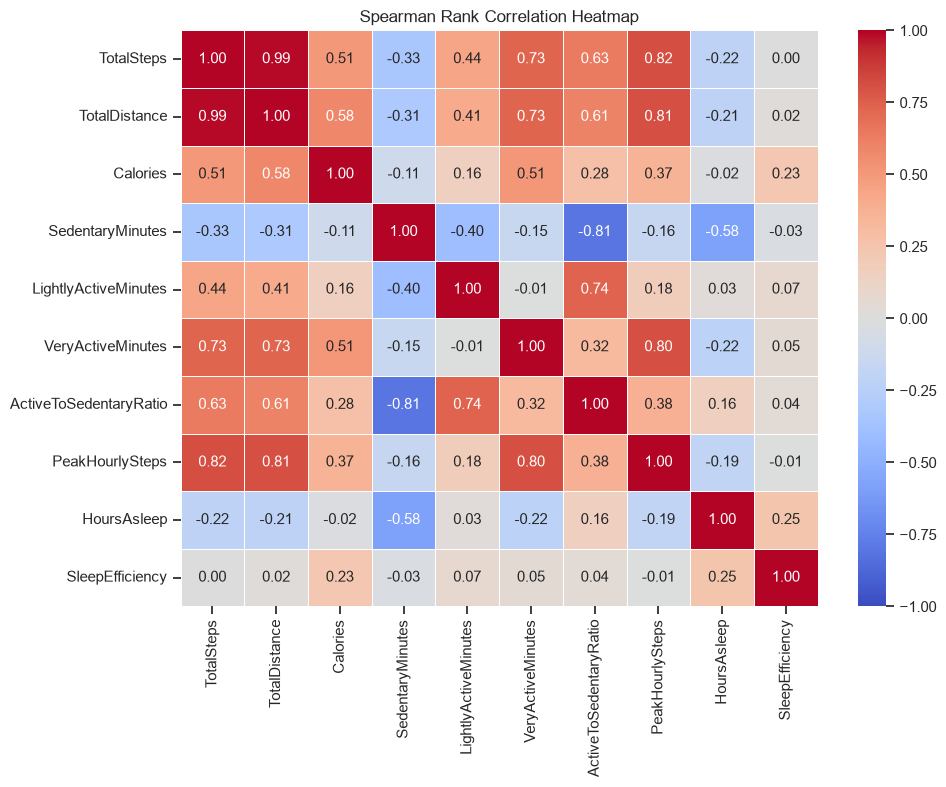

In [210]:
#heatmap of daily correlation matrix
daily_corr_matrix = df_daily_valid_wear[daily_corr_cols].corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(
    daily_corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title("Spearman Rank Correlation Heatmap")
plt.tight_layout()
plt.show()

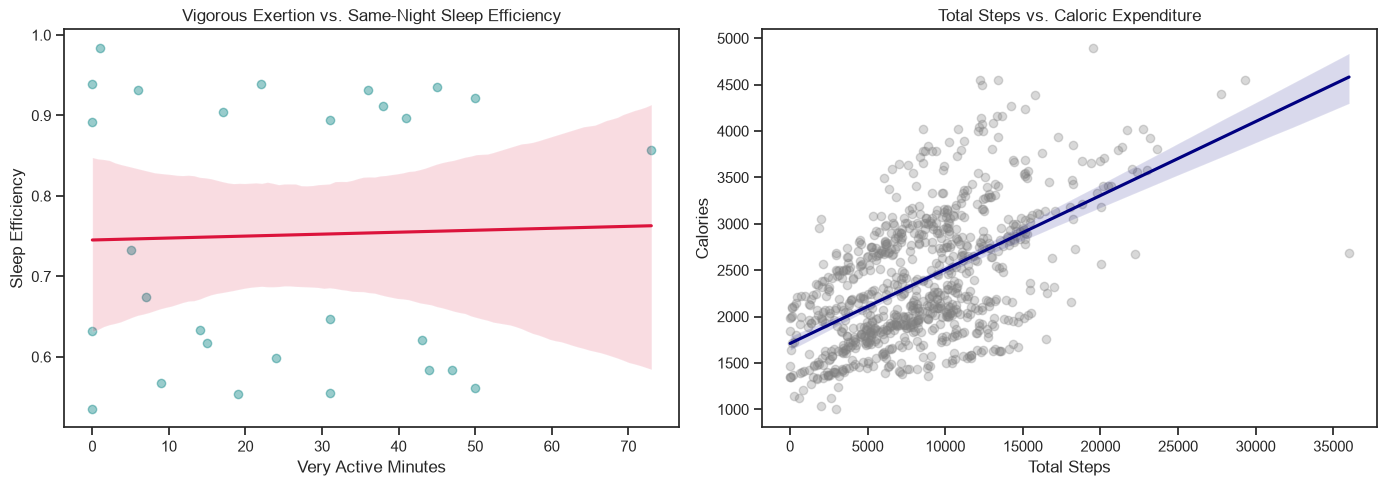

In [211]:
#Exertion vs. Sleep Efficiency

# filtering paired data to actual nocturnal sessions (excluding naps)
nocturnal_paired = df_daily_paired[
    df_daily_paired['SleepCategory'].isin(['Short Sleep', 'Full Sleep'])
].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#scatter plot: VeryActiveMinutes vs Same-Night SleepEfficiency
sns.regplot(
    data=nocturnal_paired,
    x='VeryActiveMinutes',
    y='SleepEfficiency',
    ax=axes[0],
    scatter_kws={'alpha': 0.4, 'color': 'teal'},
    line_kws={'color': 'crimson'}
)
axes[0].set_title("Vigorous Exertion vs. Same-Night Sleep Efficiency")
axes[0].set_xlabel("Very Active Minutes")
axes[0].set_ylabel("Sleep Efficiency")

#scatter plot: Daily Steps vs Caloric Burn
sns.regplot(
    data=df_daily_valid_wear,
    x='TotalSteps',
    y='Calories',
    ax=axes[1],
    scatter_kws={'alpha': 0.3, 'color': 'gray'},
    line_kws={'color': 'navy'}
)
axes[1].set_title("Total Steps vs. Caloric Expenditure")
axes[1].set_xlabel("Total Steps")
axes[1].set_ylabel("Calories")

plt.tight_layout()
plt.show()


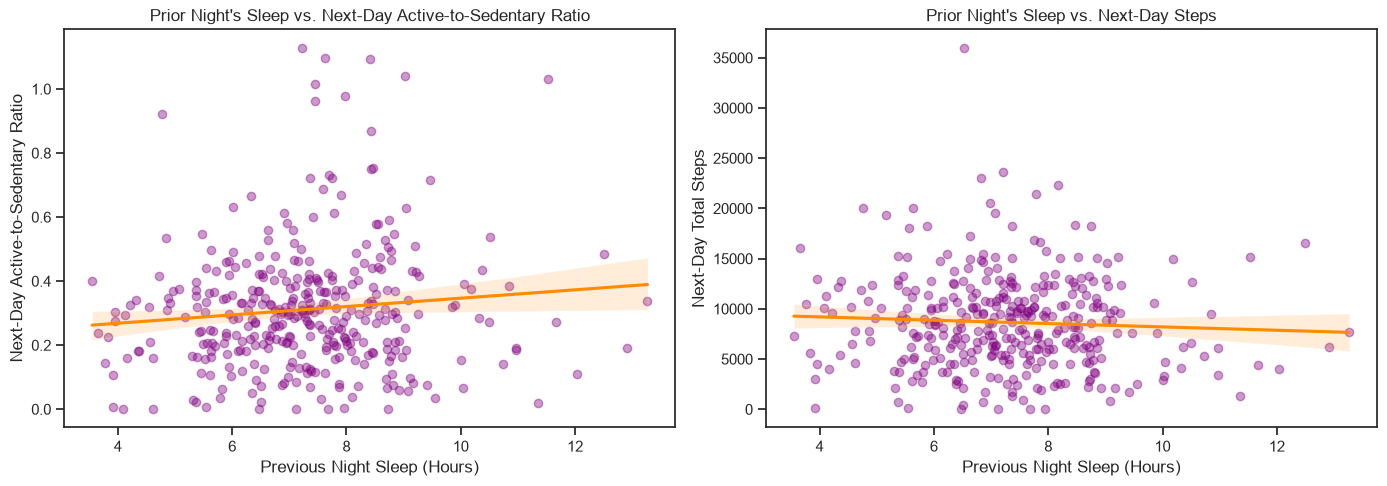

In [212]:
#directional sleep lag vs. next-day activity 

# Select rows with a valid consecutive previous-night nocturnal sleep
lag_valid = df_daily_valid_wear[
    (df_daily_valid_wear['PrevNight_HoursAsleep'].notna()) &
    (df_daily_valid_wear['PrevNight_HoursAsleep'] >= 3.0)
].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# lagged sleep vs next-day active-to-sedentary ratio
sns.regplot(
    data=lag_valid,
    x='PrevNight_HoursAsleep',
    y='ActiveToSedentaryRatio',
    ax=axes[0],
    scatter_kws={'alpha': 0.4, 'color': 'purple'},
    line_kws={'color': 'darkorange'}
)
axes[0].set_title("Prior Night's Sleep vs. Next-Day Active-to-Sedentary Ratio")
axes[0].set_xlabel("Previous Night Sleep (Hours)")
axes[0].set_ylabel("Next-Day Active-to-Sedentary Ratio")

# lagged sleep vs next-day total steps
sns.regplot(
    data=lag_valid,
    x='PrevNight_HoursAsleep',
    y='TotalSteps',
    ax=axes[1],
    scatter_kws={'alpha': 0.4, 'color': 'purple'},
    line_kws={'color': 'darkorange'}
)
axes[1].set_title("Prior Night's Sleep vs. Next-Day Steps")
axes[1].set_xlabel("Previous Night Sleep (Hours)")
axes[1].set_ylabel("Next-Day Total Steps")

plt.tight_layout()
plt.show()

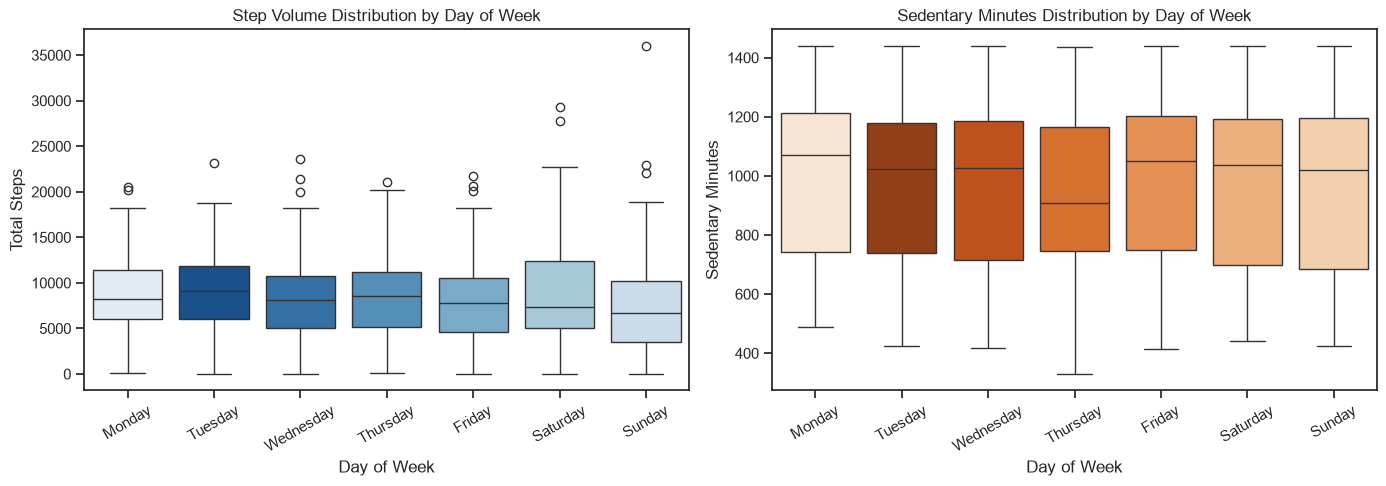

In [213]:
#day of the week analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#ordering days
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

#total steps by day of week
sns.boxplot(
    data=df_daily_valid_wear,
    x='Day_of_the_week',
    y='TotalSteps',
    order=day_order,
    hue='Day_of_the_week', 
    palette='Blues_r',
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Step Volume Distribution by Day of Week")
axes[0].set_xlabel("Day of Week")
axes[0].set_ylabel("Total Steps")
axes[0].tick_params(axis='x', rotation=30)

#sedentary minutes by day of week
sns.boxplot(
    data=df_daily_valid_wear,
    x='Day_of_the_week',
    y='SedentaryMinutes',
    order=day_order,
    hue='Day_of_the_week',  
    palette='Oranges_r',
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Sedentary Minutes Distribution by Day of Week")
axes[1].set_xlabel("Day of Week")
axes[1].set_ylabel("Sedentary Minutes")
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

8. Possible hypothesis for further statistical modeling:
* Reduced nocturnal sleep duration on night $t-1$ significantly lowers an individual's active-to-sedentary movement ratio on day $t$. 

* Weekend days exhibit significantly altered step volume and sedentary duration compared to weekday routines when controlling for personal baselines.

* Higher daily vigorous physical activity improves same-night sleep efficiency after adjusting for total caloric expenditure and sedentary time.


9. Exporting dataframes ready for analysis

In [214]:
#valid daytime wear dataset
df_daily_valid_wear.to_csv("daily_valid_wear.csv", index=False)

#paired activity-sleep dataset
df_daily_paired.to_csv("daily_paired_sleep.csv", index=False)

print("Export Complete:")
print(f" - daily_features_clean.csv: {df_daily_clean.shape}")
print(f" - daily_valid_wear.csv:      {df_daily_valid_wear.shape}")
print(f" - daily_paired_sleep.csv:     {df_daily_paired.shape}")

Export Complete:
 - daily_features_clean.csv: (940, 28)
 - daily_valid_wear.csv:      (850, 29)
 - daily_paired_sleep.csv:     (397, 27)
